In [1]:
import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import random

def fijar_semillas(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
class Conv1DAutoencoder(nn.Module):
    def __init__(self, input_channels=2, seq_len=61, bottleneck_dim=1):
        super().__init__()

        self.input_channels = input_channels
        self.seq_len = seq_len

        # ============================================================
        # ENCODER CONVOLUCIONAL
        # ============================================================
        self.encoder = nn.Sequential(
            nn.Conv1d(input_channels, 64, kernel_size=7, stride=1, padding=1),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),   # 61 → 28

            nn.Conv1d(64, 128, kernel_size=5, stride=1, padding=0),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),   # 24 → 12

            nn.Conv1d(128, 256, kernel_size=3, stride=1, padding=0),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),   # 10 → 5
        )

        self.flatten = nn.Flatten()

        # ============================================================
        # FC ENCODER (Bottleneck)
        # ============================================================
        self.fc_enc = nn.Sequential(
            nn.Linear(256 * 5, 128),
            nn.ELU(),
            nn.Linear(128, 64),
            nn.ELU(),
            nn.Linear(64, 32),
            nn.ELU(),
            nn.Linear(32, bottleneck_dim),
            nn.ELU()
        )

        # ============================================================
        # FC DECODER
        # ============================================================
        self.fc_dec = nn.Sequential(
            nn.Linear(bottleneck_dim, 32),
            nn.ELU(),
            nn.Linear(32, 64),
            nn.ELU(),
            nn.Linear(64, 128),
            nn.ELU(),
            nn.Linear(128, input_channels * seq_len),
        )

    def forward(self, x):
        x_enc = self.encoder(x)
        x_flat = self.flatten(x_enc)
        z = self.fc_enc(x_flat)
        x_dec = self.fc_dec(z)
        x_dec = x_dec.view(-1, self.input_channels, self.seq_len)
        return x_dec


In [4]:
def entrenar_cae_por_clase(
    X_train,
    model_class,
    cultivo,
    input_channels,
    seq_len=61,
    bottleneck_dim=1,
    batch_size=128,
    epochs=20,
    lr=1e-3,
    device='cpu',
    ruta_modelo=None,
    verbose=False,
):
    if not isinstance(X_train, torch.Tensor):
        X_train = torch.as_tensor(X_train, dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(X_train),
        batch_size=batch_size,
        shuffle=True
    )

    model = model_class(
        input_channels=input_channels,
        seq_len=seq_len,
        bottleneck_dim=bottleneck_dim
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist_train = []
    for epoch in range(epochs):
        model.train()
        loss_epoch = 0.0
        for (x_batch,) in loader:
            x_batch = x_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_batch), x_batch)
            loss.backward()
            optimizer.step()
            loss_epoch += loss.item() * x_batch.size(0)
        loss_epoch /= len(loader.dataset)
        hist_train.append(loss_epoch)
        if verbose:
            print(f"Epoch {epoch+1:02d}/{epochs} - {cultivo} - Train MSE: {loss_epoch:.6f}")

    if ruta_modelo is not None:
        os.makedirs(os.path.dirname(ruta_modelo) or ".", exist_ok=True)
        torch.save(
            {
                'model_state_dict': model.state_dict(),
                'loss': hist_train[-1]
            },
            ruta_modelo
        )

    return model, hist_train


def predict_pixels(X, labels, cae_models, batch_size=4096, device='cuda'):
    """
    Calcula el MSE a nivel de píxel para cada modelo experto.
    Devuelve la clase con menor error de reconstrucción.
    """
    if isinstance(X, np.ndarray):
        X = torch.as_tensor(X, dtype=torch.float32)

    if isinstance(labels, torch.Tensor):
        labels_arr = labels.cpu().numpy()
    elif isinstance(labels, list):
        labels_arr = np.array(labels)
    else:
        labels_arr = labels

    num_samples = X.shape[0]
    class_ids   = sorted(list(cae_models.keys()))
    num_classes = len(class_ids)

    mse_matrix = np.zeros((num_samples, num_classes), dtype=np.float32)
    criterion  = nn.MSELoss(reduction='none')

    for col_idx, c_id in enumerate(class_ids):
        model = cae_models[c_id].to(device)
        model.eval()
        col_mse = []

        with torch.no_grad():
            for start_idx in range(0, num_samples, batch_size):
                end_idx = min(start_idx + batch_size, num_samples)
                X_batch = X[start_idx:end_idx].to(device)
                X_recon = model(X_batch)
                batch_mse = criterion(X_batch, X_recon).mean(
                    dim=tuple(range(1, X_batch.ndim))
                )
                col_mse.append(batch_mse.cpu().numpy())

        mse_matrix[:, col_idx] = np.concatenate(col_mse)

    min_indices      = np.argmin(mse_matrix, axis=1)
    class_map        = np.array(class_ids)
    candidate_classes = class_map[min_indices]

    is_trustworthy = (candidate_classes == labels_arr)
    is_suspicious  = ~is_trustworthy

    return {
        'mse_matrix':        mse_matrix,
        'candidate_classes': candidate_classes,
        'is_trustworthy':    is_trustworthy,
        'is_suspicious':     is_suspicious
    }


In [5]:
INPUT_CHANNELS = 2
SEQ_LEN        = 61

# ============================================================
# CARGA DEL DATASET
# ============================================================
data = torch.load(
    "/home/angelo/MyStore/Proyecto Investigador/2017/dataset_split_2017/dataset_split_2017_(backscatter)_v1.pt",
    weights_only=False
)

datos_train_por_cultivo = data["train"]

datos_limpios = {}
for clase, datos in datos_train_por_cultivo.items():
    X = torch.tensor(datos["X"]).float()
    X = X.reshape(X.shape[0], INPUT_CHANNELS, SEQ_LEN)
    datos_limpios[clase] = {
        "X":        X,
        "coords":   torch.tensor(datos["coords"]),
        "parcelas": torch.tensor(datos["parcelas"])
    }

print("Dataset cargado.")
for clase, datos in datos_limpios.items():
    print(f"  {clase}: X{tuple(datos['X'].shape)}")

Dataset cargado.
  Alfalfa: X(15860, 2, 61)
  Carrot: X(7925, 2, 61)
  Chickpea: X(1743, 2, 61)
  Cotton: X(238443, 2, 61)
  Fallow: X(2756, 2, 61)
  Maize: X(25367, 2, 61)
  Onion: X(5426, 2, 61)
  Pepper: X(2129, 2, 61)
  Potato: X(1361, 2, 61)
  Pumpkin: X(3589, 2, 61)
  Quinoa: X(3959, 2, 61)
  SugarBeet: X(83536, 2, 61)
  Sunflower: X(24342, 2, 61)
  SweetPotato: X(4465, 2, 61)
  Tomato: X(131278, 2, 61)
  Wheat: X(16783, 2, 61)


Utilizando dispositivo: cuda

 PASADA DE PURGA 1/10
Entrenando CAE (Alfalfa) - Muestras actuales: (15860, 2, 61)
Entrenando CAE (Carrot) - Muestras actuales: (7925, 2, 61)
Entrenando CAE (Chickpea) - Muestras actuales: (1743, 2, 61)
Entrenando CAE (Cotton) - Muestras actuales: (238443, 2, 61)
Entrenando CAE (Fallow) - Muestras actuales: (2756, 2, 61)
Entrenando CAE (Maize) - Muestras actuales: (25367, 2, 61)
Entrenando CAE (Onion) - Muestras actuales: (5426, 2, 61)
Entrenando CAE (Pepper) - Muestras actuales: (2129, 2, 61)
Entrenando CAE (Potato) - Muestras actuales: (1361, 2, 61)
Entrenando CAE (Pumpkin) - Muestras actuales: (3589, 2, 61)
Entrenando CAE (Quinoa) - Muestras actuales: (3959, 2, 61)
Entrenando CAE (SugarBeet) - Muestras actuales: (83536, 2, 61)
Entrenando CAE (Sunflower) - Muestras actuales: (24342, 2, 61)
Entrenando CAE (SweetPotato) - Muestras actuales: (4465, 2, 61)
Entrenando CAE (Tomato) - Muestras actuales: (131278, 2, 61)
Entrenando CAE (Wheat) - Muestras actuales

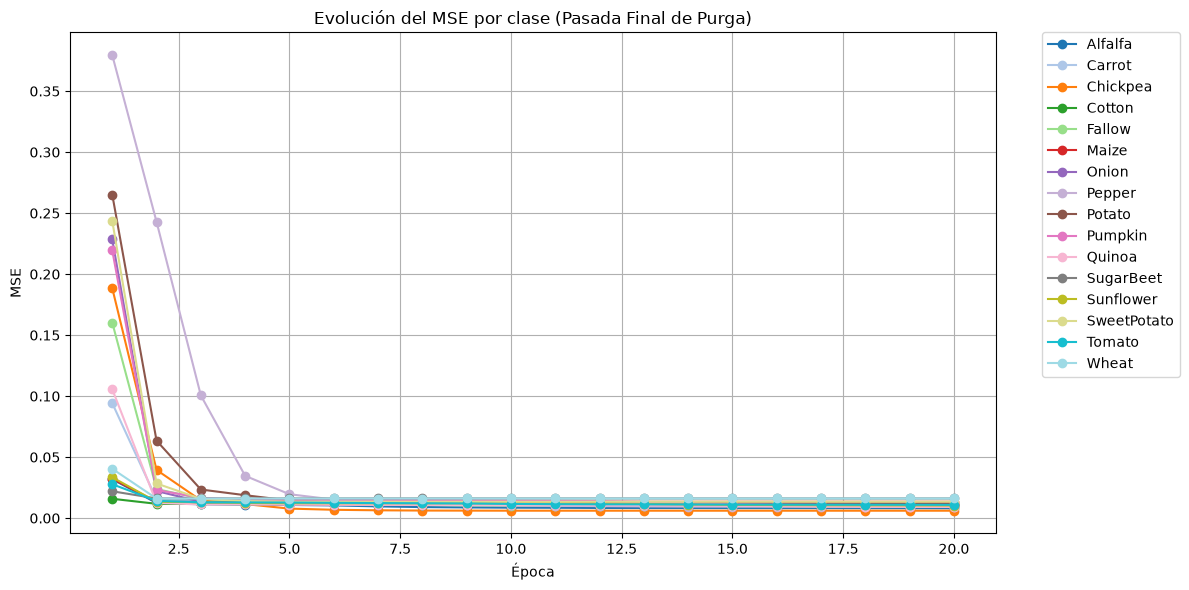

In [ ]:
# ============================================================
# CONFIGURACIÓN GLOBAL
# ============================================================
path_modelos = (
    "/home/angelo/MyStore/Proyecto Investigador/2017/"
    "Modelos_temporales_2017_FARMSAR_BOTTLENECK_DIM_1_10pass_v1"
)
os.makedirs(path_modelos, exist_ok=True)

BOTTLENECK_DIM     = 1
EPOCHS             = 20
BATCH_SIZE         = 128
LR                 = 1e-3
NUM_PURGE_PASSES   = 10
MIN_MUESTRAS_CLASE = 500   # única guardia: mínimo absoluto de muestras

SEED = 42
fijar_semillas(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Utilizando dispositivo: {device}")

# Copia de trabajo que se irá purificando
X_purificado_train = {
    clase: datos["X"].clone()
    for clase, datos in datos_limpios.items()
}

# ============================================================
# BUCLE ITERATIVO DE PURGA FARMSAR (10 PASADAS)
# ============================================================
modelos_finales  = {}
historial_global = {}
historial_tamanos = {
    clase: [len(datos["X"])]
    for clase, datos in datos_limpios.items()
}

for pasada in range(1, NUM_PURGE_PASSES + 1):

    print("\n" + "=" * 60)
    print(f" PASADA DE PURGA {pasada}/{NUM_PURGE_PASSES}")
    print("=" * 60)

    modelos_pasada = {}

    # --------------------------------------------------------
    # A. Entrenar un CAE experto por cada cultivo
    # --------------------------------------------------------
    for clase in list(X_purificado_train.keys()):

        X_tr = X_purificado_train[clase]

        if len(X_tr) == 0:
            print(f"  [{clase}] ⚠ Sin muestras, se elimina.")
            del X_purificado_train[clase]
            continue

        print(f"Entrenando CAE ({clase}) - Muestras actuales: {tuple(X_tr.shape)}")

        ruta_guardado = (
            f"{path_modelos}/cae_pasada_{pasada}_{clase}.pth"
            if pasada == NUM_PURGE_PASSES else None
        )

        model, h_tr = entrenar_cae_por_clase(
            X_tr,
            Conv1DAutoencoder,
            clase,
            input_channels=INPUT_CHANNELS,
            seq_len=SEQ_LEN,
            bottleneck_dim=BOTTLENECK_DIM,
            batch_size=BATCH_SIZE,
            epochs=EPOCHS,
            lr=LR,
            device=device,
            ruta_modelo=ruta_guardado,
            verbose=False,
        )
        modelos_pasada[clase] = model

        if pasada == NUM_PURGE_PASSES:
            historial_global[clase] = {"train": h_tr}

    # --------------------------------------------------------
    # B. Purgar o finalizar
    # --------------------------------------------------------
    if pasada < NUM_PURGE_PASSES:

        print("\n Evaluando y purgando muestras sospechosas...")

        clases_en_riesgo = []

        for clase in list(X_purificado_train.keys()):

            X_actual = X_purificado_train[clase]

            if len(X_actual) == 0:
                print(f"  [{clase}] ⚠ Ya estaba vacía, se elimina.")
                del X_purificado_train[clase]
                continue

            labels_dummy = np.array([clase] * len(X_actual))

            res_eval = predict_pixels(
                X_actual, labels_dummy, modelos_pasada,
                batch_size=BATCH_SIZE, device=device
            )

            mask_confiable  = res_eval['is_trustworthy']
            mask_tensor     = torch.from_numpy(mask_confiable)
            num_conservados = int(mask_confiable.sum())
            num_eliminados  = len(mask_confiable) - num_conservados

            # Única guardia: mínimo absoluto de muestras
            if num_conservados < MIN_MUESTRAS_CLASE:
                print(
                    f"  [{clase}] Solo quedarían {num_conservados} muestras "
                    f"(< mínimo {MIN_MUESTRAS_CLASE}). Se congela sin purgar."
                )
                clases_en_riesgo.append(clase)

            else:
                X_purificado_train[clase] = X_actual[mask_tensor]
                print(
                    f"  [{clase}] Retenidas: {num_conservados}/{len(mask_confiable)} | "
                    f"Descartadas: {num_eliminados}"
                )

        # --- Resumen de la pasada ---
        print(f"\n  Clases congeladas esta pasada : {len(clases_en_riesgo)}")
        if clases_en_riesgo:
            print(f"  → {clases_en_riesgo}")

        clases_activas = list(X_purificado_train.keys())
        print(
            f"  Clases activas para pasada {pasada+1}: "
            f"{len(clases_activas)}/{len(datos_limpios)}"
        )

        if len(clases_activas) < len(datos_limpios):
            clases_perdidas = set(datos_limpios.keys()) - set(clases_activas)
            print(f" Clases perdidas definitivamente: {clases_perdidas}")

        # --- Registrar tamaños tras la purga ---
        for c in datos_limpios.keys():
            if c in X_purificado_train:
                historial_tamanos[c].append(len(X_purificado_train[c]))
            else:
                historial_tamanos[c].append(historial_tamanos[c][-1])

    else:
        modelos_finales = modelos_pasada

print("\n¡Proceso de purga e iteración completado!")

# ============================================================
# TABLA DE EVOLUCIÓN
# ============================================================
print("\n" + "=" * 90)
print("EVOLUCIÓN DE MUESTRAS POR CLASE A LO LARGO DE LAS PASADAS")
print("=" * 90)
print(f"{'Cultivo':<15}{'Inicial':>10}", end="")
for p in range(1, NUM_PURGE_PASSES):
    print(f"{'P'+str(p):>8}", end="")
print(f"{'%Final':>9}")
print("-" * 90)

for clase, hist in historial_tamanos.items():
    print(f"{clase:<15}{hist[0]:>10,}", end="")
    for n in hist[1:]:
        print(f"{n:>8,}", end="")
    pct = hist[-1] / hist[0] * 100 if hist[0] > 0 else 0
    print(f"{pct:>8.1f}%")

# ============================================================
# GRÁFICO DE PÉRDIDAS DE LA PASADA FINAL
# ============================================================
cultivos = list(historial_global.keys())
colores  = cm.tab20(np.linspace(0, 1, len(cultivos)))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for color, clase in zip(colores, cultivos):
    epocas = range(1, len(historial_global[clase]["train"]) + 1)
    losses = historial_global[clase]["train"]

    # --- Escala lineal (original) ---
    axes[0].plot(epocas, losses, marker='o', color=color, label=clase)

    # --- Escala logarítmica ---
    axes[1].plot(epocas, losses, marker='o', color=color, label=clase)

# Gráfico izquierdo — lineal
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE")
axes[0].set_title("Escala lineal")
axes[0].grid(True)

# Gráfico derecho — logarítmico
axes[1].set_yscale("log")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MSE (log)")
axes[1].set_title("Escala logarítmica")
axes[1].grid(True, which="both")   # ← grid en escala log incluye líneas menores

# Leyenda compartida fuera
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(
    handles, labels,
    bbox_to_anchor=(1.01, 0.5),
    loc='center left',
    borderaxespad=0.
)

fig.suptitle("Evolución del MSE por clase (Pasada Final de Purga)", fontsize=13)
plt.tight_layout()
plt.savefig(
    f"{path_modelos}/evolucion_perdidas_final.png",
    bbox_inches='tight'
)
plt.show()


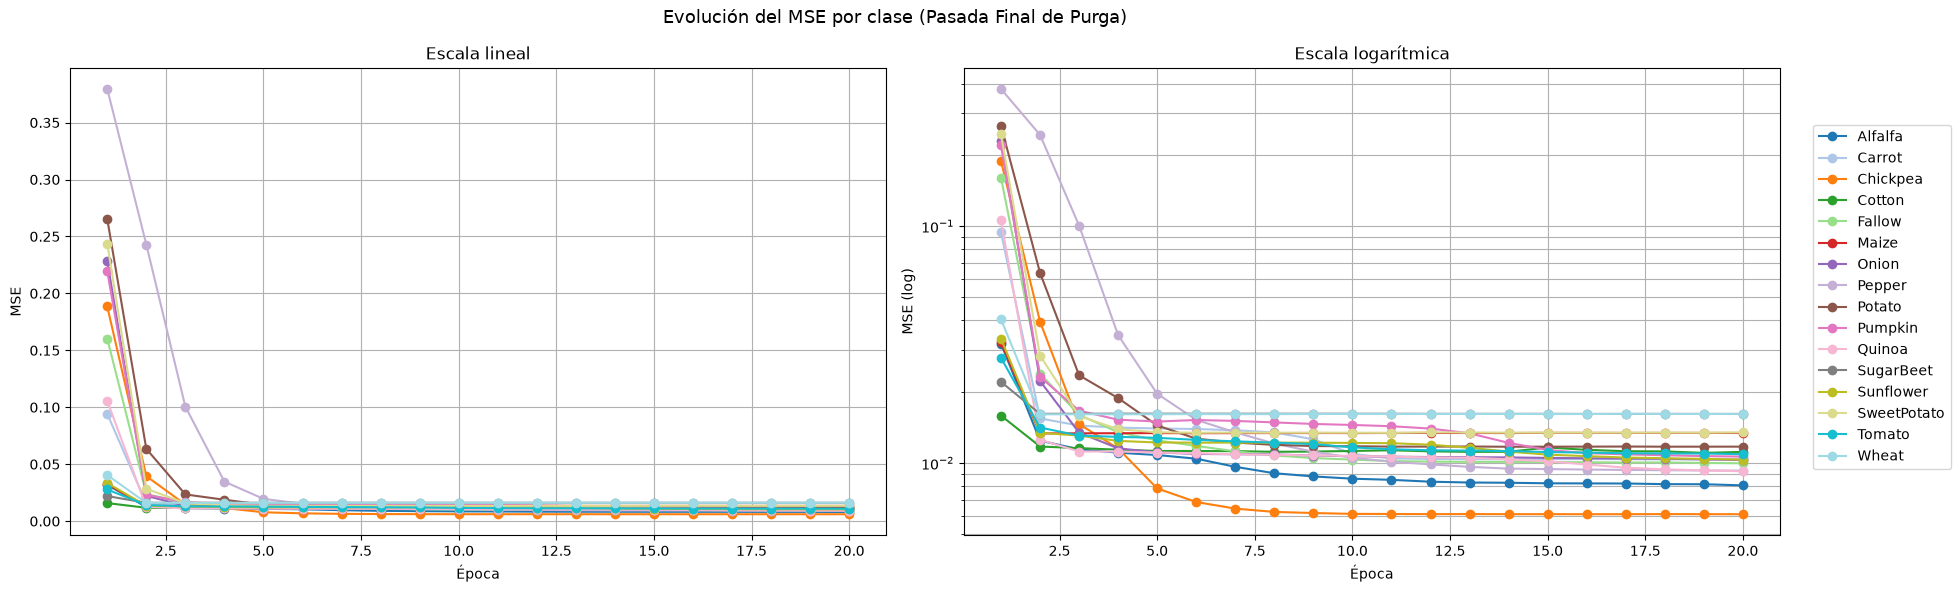

In [7]:
cultivos = list(historial_global.keys())
colores  = cm.tab20(np.linspace(0, 1, len(cultivos)))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for color, clase in zip(colores, cultivos):
    epocas = range(1, len(historial_global[clase]["train"]) + 1)
    losses = historial_global[clase]["train"]

    # --- Escala lineal (original) ---
    axes[0].plot(epocas, losses, marker='o', color=color, label=clase)

    # --- Escala logarítmica ---
    axes[1].plot(epocas, losses, marker='o', color=color, label=clase)

# Gráfico izquierdo — lineal
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE")
axes[0].set_title("Escala lineal")
axes[0].grid(True)

# Gráfico derecho — logarítmico
axes[1].set_yscale("log")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MSE (log)")
axes[1].set_title("Escala logarítmica")
axes[1].grid(True, which="both")   # ← grid en escala log incluye líneas menores

# Leyenda compartida fuera
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(
    handles, labels,
    bbox_to_anchor=(1.01, 0.5),
    loc='center left',
    borderaxespad=0.
)

fig.suptitle("Evolución del MSE por clase (Pasada Final de Purga)", fontsize=13)
plt.tight_layout()
plt.savefig(
    f"{path_modelos}/evolucion_perdidas_final.png",
    bbox_inches='tight'
)
plt.show()
